In [10]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

ds = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
#三维数据（时间、经、纬）
sst_all = ds["sst"]
#按坐标选择数据
nino34_sst = sst_all.sel(lat=slice(-5, 5), lon=slice(190, 240))
#在纬度、经度两个维度求平均
nino34_mean = nino34_sst.mean(dim=["lat", "lon"])
#按月份分组
monthly_clim = nino34_mean.groupby("time.month").mean(dim="time")
#消除季节冷暖
sst_anom = nino34_mean.groupby("time.month") - monthly_clim
nino34_oni = sst_anom.rolling(time=3, center=True).mean()

print(monthly_clim.values)

[26.56812  26.742603 27.239906 27.694027 27.795525 27.598068 27.199272
 26.824581 26.738201 26.717514 26.693666 26.613451]


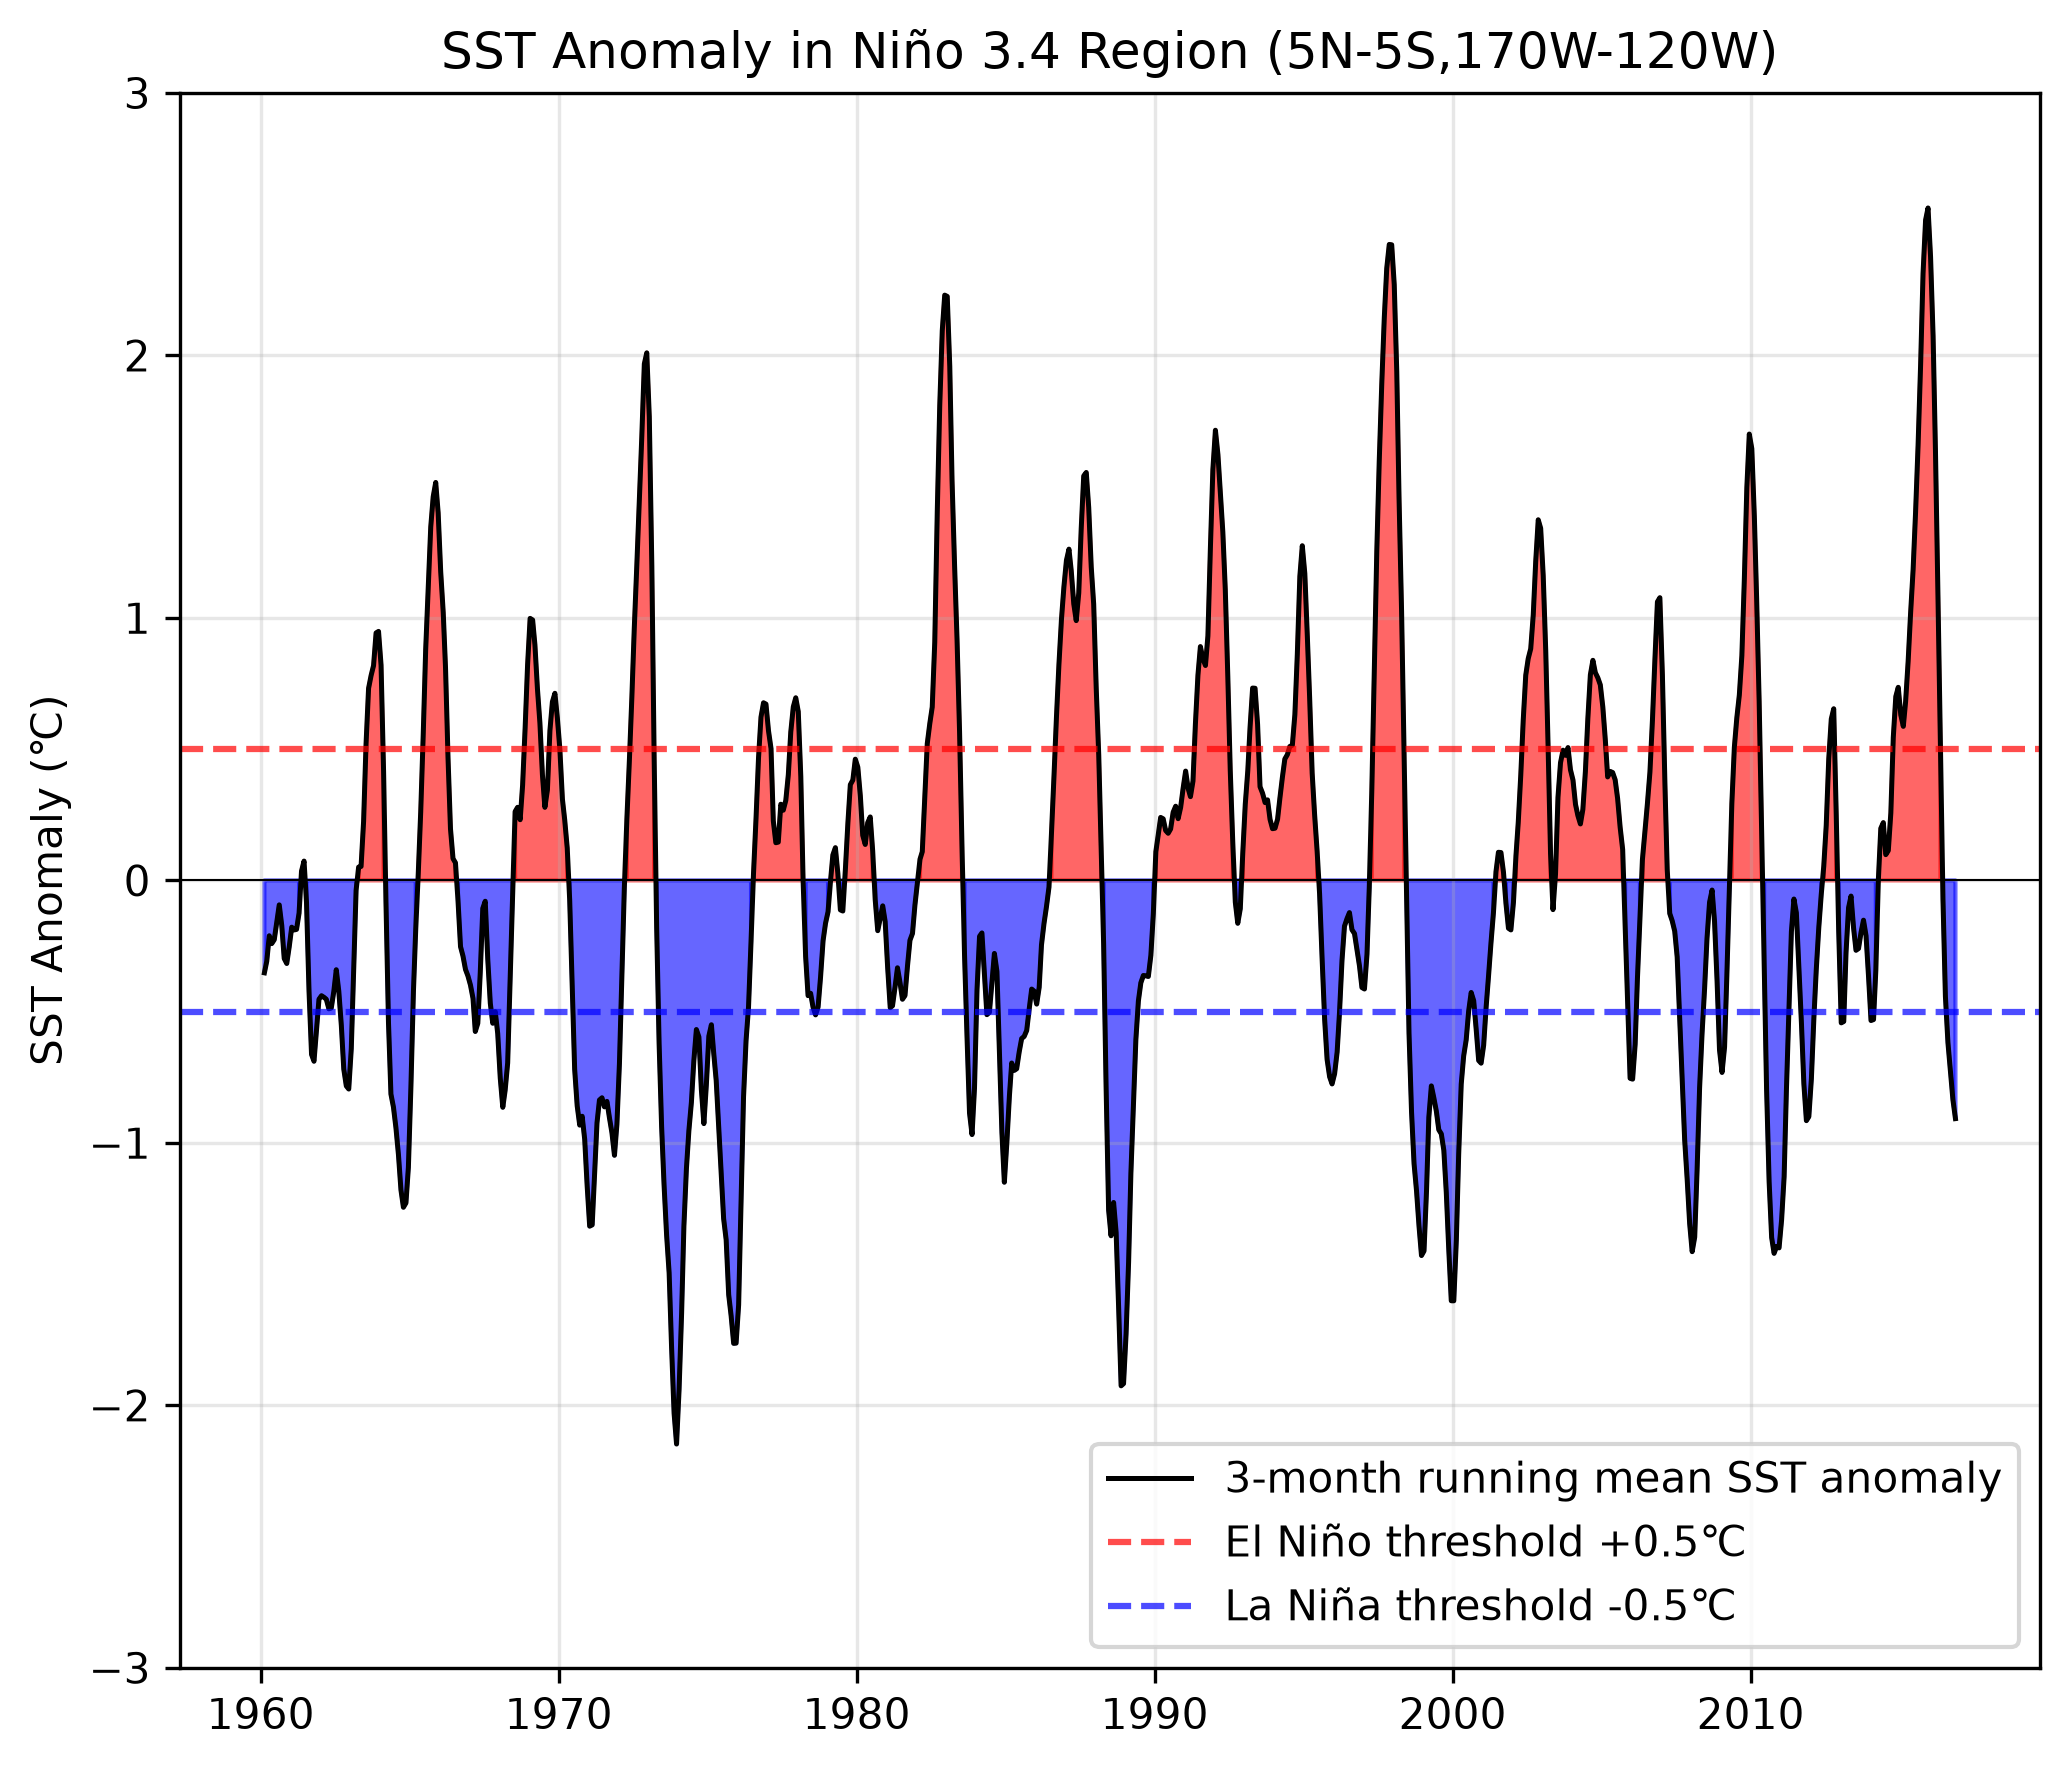

In [15]:
plt.figure(figsize=(7, 6), dpi=300)
#把 oni 里面的时间提取出来，变成 numpy 数组
time_arr = nino34_oni["time"].values
#把 ONI 指数数值提取成数组
oni_vals = nino34_oni.values

threshold_el = 0.5
threshold_la = -0.5

plt.plot(time_arr, oni_vals, color="black", lw=1.2, label="3-month running mean SST anomaly")
plt.axhline(y=threshold_el, color='red', linestyle="--", alpha=0.7, label="El Niño threshold +0.5℃")
plt.axhline(y=threshold_la, color='blue', linestyle="--", alpha=0.7, label="La Niña threshold -0.5℃")
plt.axhline(y=0, color="k", lw=0.5)

plt.fill_between(time_arr, oni_vals, 0, where=(oni_vals > 0),
                 color="red", alpha=0.6)
plt.fill_between(time_arr, oni_vals, 0, where=(oni_vals < 0),
                 color="blue", alpha=0.6)

plt.ylim([-3.0, 3.0])
plt.ylabel("SST Anomaly (℃)")
plt.title("SST Anomaly in Niño 3.4 Region (5N-5S,170W-120W)")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("SST Anomaly in Niño 3.4 Region (5N-5S,170W-120W).png", dpi=300, bbox_inches="tight")
plt.show()